In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_pre = pd.read_csv("WDICSV.csv")

#Loading Indicators
indicators = ['NY.GDP.PCAP.CD', 'NY.GDP.MKTP.KD.ZG', 'FP.CPI.TOTL.ZG', 'SL.UEM.TOTL.ZS', 'NE.TRD.GNFS.ZS', 'NE.GDI.TOTL.ZS', 'SP.DYN.LE00.IN', 'SP.URB.TOTL.IN.ZS', 'IT.NET.USER.ZS', 'EG.ELC.ACCS.ZS', 'SE.SEC.ENRR']

In [3]:
data_pre = data_pre[data_pre['Indicator Code'].isin(indicators)] #Taking rows having selected Indicators
data_pre.isna().sum().sort_values()[:5]

Country Name        0
Country Code        0
Indicator Name      0
Indicator Code      0
2015              261
dtype: int64

In [4]:
#2015 has the least number of missing values
data_fil = data_pre.pivot_table(index=['Country Name', 'Country Code'], columns='Indicator Code', values='2015').reset_index()
#Pivoting to get 2015 values with Indicators as columns

In [5]:
print(len(data_fil))

265


In [6]:
url = 'https://api.worldbank.org/v2/country?format=json&per_page=400'
response = requests.get(url)
data_cat = response.json()
#World Bank Country API

In [7]:
countries = pd.json_normalize(data_cat[1])
countries = countries.rename(columns = {'id' : 'Country Code'})
countries = countries[['Country Code','region.value','lendingType.value','incomeLevel.value']]
countries = countries[countries['region.value'] != 'Aggregates'] #Removing aggregate rows

In [8]:
data = data_fil.merge(countries, on='Country Code', how='inner')
#This removed aggregates present in WDI data, since country codes for aggregates (like World, Upper high income) were removed and hence no aggregates merged.

In [9]:
data

,Country Name,Country Code,EG.ELC.ACCS.ZS,FP.CPI.TOTL.ZG,IT.NET.USER.ZS,NE.GDI.TOTL.ZS,NE.TRD.GNFS.ZS,NY.GDP.MKTP.KD.ZG,NY.GDP.PCAP.CD,SE.SEC.ENRR,SL.UEM.TOTL.ZS,SP.DYN.LE00.IN,SP.URB.TOTL.IN.ZS,region.value,lendingType.value,incomeLevel.value
0,Afghanistan,AFG,71.5,-0.661709,8.260000,NaN,NaN,1.451315,565.569730,53.150108,9.032,62.270000,24.464912,"Middle East, North Africa, Afghanistan & Pakistan",IDA,Low income
1,Albania,ALB,100.0,1.896174,56.900002,27.813465,71.279448,2.227704,4199.539129,102.440729,17.193,78.358000,55.157929,Europe & Central Asia,IBRD,Upper middle income
2,Algeria,DZA,99.4,4.784447,38.200001,51.779613,53.204623,3.200000,4685.059027,NaN,11.206,75.159000,70.143307,"Middle East, North Africa, Afghanistan & Pakistan",IBRD,Upper middle income
3,American Samoa,ASM,NaN,NaN,NaN,NaN,162.407132,3.149606,12727.410265,NaN,NaN,72.654000,84.668671,East Asia & Pacific,Not classified,High income
4,Andorra,AND,100.0,NaN,87.900002,NaN,NaN,1.434140,38654.934722,91.296219,NaN,84.532000,88.518085,Europe & Central Asia,Not classified,High income
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,Virgin Islands (U.S.),VIR,100.0,NaN,54.839137,NaN,84.766585,-0.425080,34007.352941,NaN,11.649,79.017073,94.941332,Latin America & Caribbean,Not classified,High income
213,West Bank and Gaza,PSE,99.9,1.431611,56.700001,25.088031,70.780968,3.721300,3272.154324,88.390922,23.005,74.577000,85.218217,"Middle East, North Africa, Afghanistan & Pakistan",Not classified,Lower middle income
214,"Yemen, Rep.",YEM,67.4,NaN,24.085400,1.656342,30.367659,-27.994546,1362.173812,NaN,17.900,66.761000,32.388318,"Middle East, North Africa, Afghanistan & Pakistan",IDA,Low income
215,Zambia,ZMB,31.1,10.110593,8.800000,42.805116,79.865269,2.920375,1295.877887,NaN,5.951,60.728000,41.955510,Sub-Saharan Africa,IDA,Lower middle income


## Exploratory Data Analysis

### 1. Data Inspection

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country Name       217 non-null    str    
 1   Country Code       217 non-null    str    
 2   EG.ELC.ACCS.ZS     215 non-null    float64
 3   FP.CPI.TOTL.ZG     189 non-null    float64
 4   IT.NET.USER.ZS     201 non-null    float64
 5   NE.GDI.TOTL.ZS     177 non-null    float64
 6   NE.TRD.GNFS.ZS     185 non-null    float64
 7   NY.GDP.MKTP.KD.ZG  211 non-null    float64
 8   NY.GDP.PCAP.CD     212 non-null    float64
 9   SE.SEC.ENRR        155 non-null    float64
 10  SL.UEM.TOTL.ZS     187 non-null    float64
 11  SP.DYN.LE00.IN     217 non-null    float64
 12  SP.URB.TOTL.IN.ZS  217 non-null    float64
 13  region.value       217 non-null    str    
 14  lendingType.value  217 non-null    str    
 15  incomeLevel.value  217 non-null    str    
dtypes: float64(11), str(5)
memory usage: 

### For 2015
There are 217 countries \
11 Indicators which will act as variables

```Missing values for countries (Out of 217) - 
2 in Electricity access    (0.9217%)
28 in Inflation            (12.9032%)
16 in Internet users       (7.3732%)
40 in GCF                  (18.4332%)
32 in Trade                (14.7465%)
6 in GDP Growth            (2.750%)
5 in GDP per capita        (2.3041%)
62 in Secondary Enrollment (28.5714%)
30 in Unemployment         (13.8249%)
All data present for Life expectancy and Urban population

In [11]:
data.set_index('Country Name')[indicators].isna().sum(axis=1).sort_values(ascending=False)[:10] #Countries with the largest amount of missing data

Country Name
Gibraltar                    8
British Virgin Islands       7
St. Martin (French part)     7
Isle of Man                  6
American Samoa               6
Korea, Dem. People's Rep.    6
Liechtenstein                5
Channel Islands              5
Eritrea                      5
Monaco                       5
dtype: int64

In [12]:
data[indicators].describe().T

,count,mean,std,min,25%,50%,75%,max
NY.GDP.PCAP.CD,212.0,17068.360267,25280.529658,254.402585,2233.655343,6147.913295,20496.424748,170437.021129
NY.GDP.MKTP.KD.ZG,211.0,2.700007,4.509821,-27.994546,1.130550,2.920293,4.469767,24.623986
FP.CPI.TOTL.ZG,189.0,4.062122,10.975076,-3.749145,0.065290,1.437024,4.560563,121.738085
SL.UEM.TOTL.ZS,187.0,8.092743,6.015152,0.170000,3.884500,6.412000,10.754000,27.695000
NE.TRD.GNFS.ZS,185.0,89.998884,56.476070,18.378273,54.874951,74.634355,107.806616,389.405949
NE.GDI.TOTL.ZS,177.0,24.525446,9.083154,-3.945924,19.479615,23.859794,28.416408,76.782325
SP.DYN.LE00.IN,217.0,72.114401,8.223112,39.757000,66.023000,73.624390,78.275000,85.323000
SP.URB.TOTL.IN.ZS,217.0,60.447882,23.956429,13.234136,39.982442,61.737474,80.570799,100.000000
IT.NET.USER.ZS,201.0,47.857891,29.000793,1.083700,21.320000,50.139318,72.049400,98.323610
EG.ELC.ACCS.ZS,215.0,83.290233,27.086065,4.800000,73.900000,99.400000,100.000000,100.000000


In [13]:
(data[indicators].max() - data[indicators].min()).sort_values(ascending=False)
#Range of every Indicator

NY.GDP.PCAP.CD       170182.618543
NE.TRD.GNFS.ZS          371.027676
SE.SEC.ENRR             152.545009
FP.CPI.TOTL.ZG          125.487231
IT.NET.USER.ZS           97.239910
EG.ELC.ACCS.ZS           95.200000
SP.URB.TOTL.IN.ZS        86.765864
NE.GDI.TOTL.ZS           80.728249
NY.GDP.MKTP.KD.ZG        52.618532
SP.DYN.LE00.IN           45.566000
SL.UEM.TOTL.ZS           27.525000
dtype: float64

In [14]:
for col in indicators:
    print("Indicator - " + col + "\nLowest 3:")
    print(data[['Country Name', col]].sort_values(col)[:3])
    print("\n" + "Highest 3:")
    print(data[['Country Name', col]].sort_values(col, ascending=False)[:3])
    print()

Indicator - NY.GDP.PCAP.CD
Lowest 3:
                 Country Name  NY.GDP.PCAP.CD
31                    Burundi      254.402585
37   Central African Republic      366.322854
118                Madagascar      445.320069

Highest 3:
      Country Name  NY.GDP.PCAP.CD
130         Monaco   170437.021129
114  Liechtenstein   167187.157310
116     Luxembourg   105462.012584

Indicator - NY.GDP.MKTP.KD.ZG
Lowest 3:
         Country Name  NY.GDP.MKTP.KD.ZG
214       Yemen, Rep.         -27.994546
117  Macao SAR, China         -21.754008
178       South Sudan         -10.793365

Highest 3:
                 Country Name  NY.GDP.MKTP.KD.ZG
93                    Ireland          24.623986
200  Turks and Caicos Islands          11.314829
102                  Kiribati          11.265321

Indicator - FP.CPI.TOTL.ZG
Lowest 3:
       Country Name  FP.CPI.TOTL.ZG
110         Lebanon       -3.749145
216        Zimbabwe       -2.430968
36   Cayman Islands       -2.347528

Highest 3:
      Country Name  

GDP per capita has a large range: Burundi - least ($254), Monaco - largest ($170437)\
and so does GDP Growth: Yemen - least (-28%), Ireland - highest (24.62%)

South Sudan has just 4.8% electricity access, while several economies have reached 100%.\
Hong Kong has very high trade (389.41%) while lebanon got low (18.38%) trade\
Similarly Belgium has high (164.08%) secondary enrollment and South Sudan has it low (11.53%)

### 2. Analysis of feature Distributions

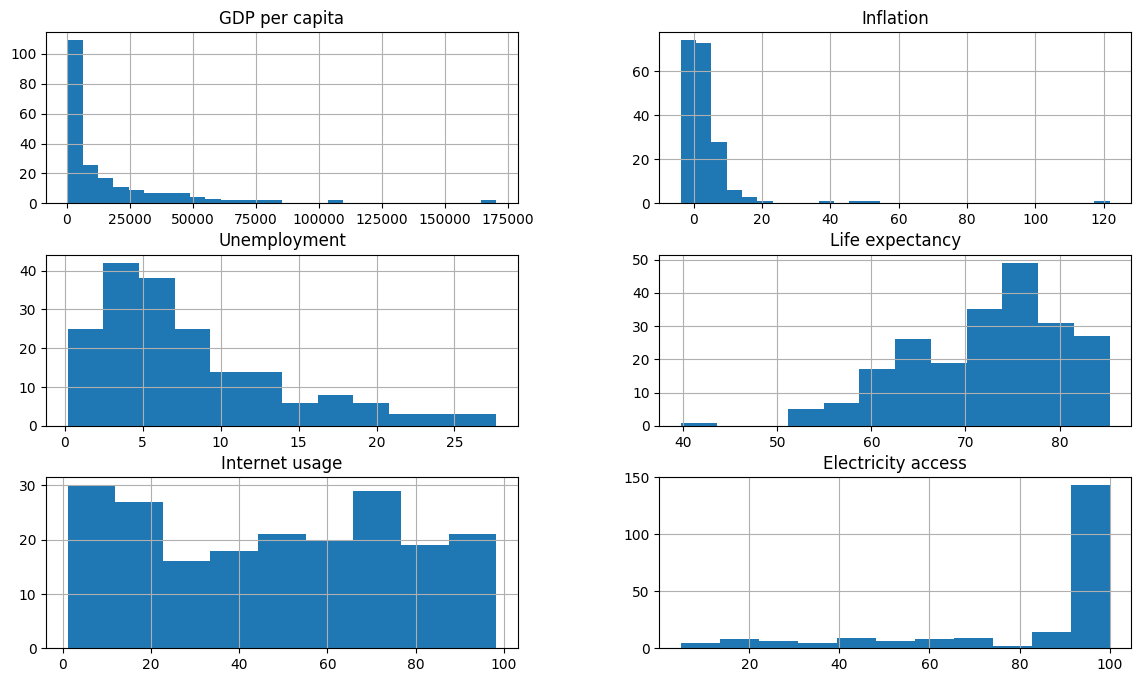

In [15]:
key_data = data[['NY.GDP.PCAP.CD', 'FP.CPI.TOTL.ZG', 'SL.UEM.TOTL.ZS', 'SP.DYN.LE00.IN', 'IT.NET.USER.ZS', 'EG.ELC.ACCS.ZS']]
key_data.rename(columns={'NY.GDP.PCAP.CD': 'GDP per capita', 'FP.CPI.TOTL.ZG': 'Inflation', 'SL.UEM.TOTL.ZS': 'Unemployment', 'SP.DYN.LE00.IN': 'Life expectancy', 'IT.NET.USER.ZS': 'Internet usage', 'EG.ELC.ACCS.ZS': 'Electricity access'}).hist(bins='auto', figsize=(14, 8));

Clearly GDP per capita, Inflation and Electricity access are extremely skewed\
GDP PC and Inflation are right skewed while Electricity access is left skewed

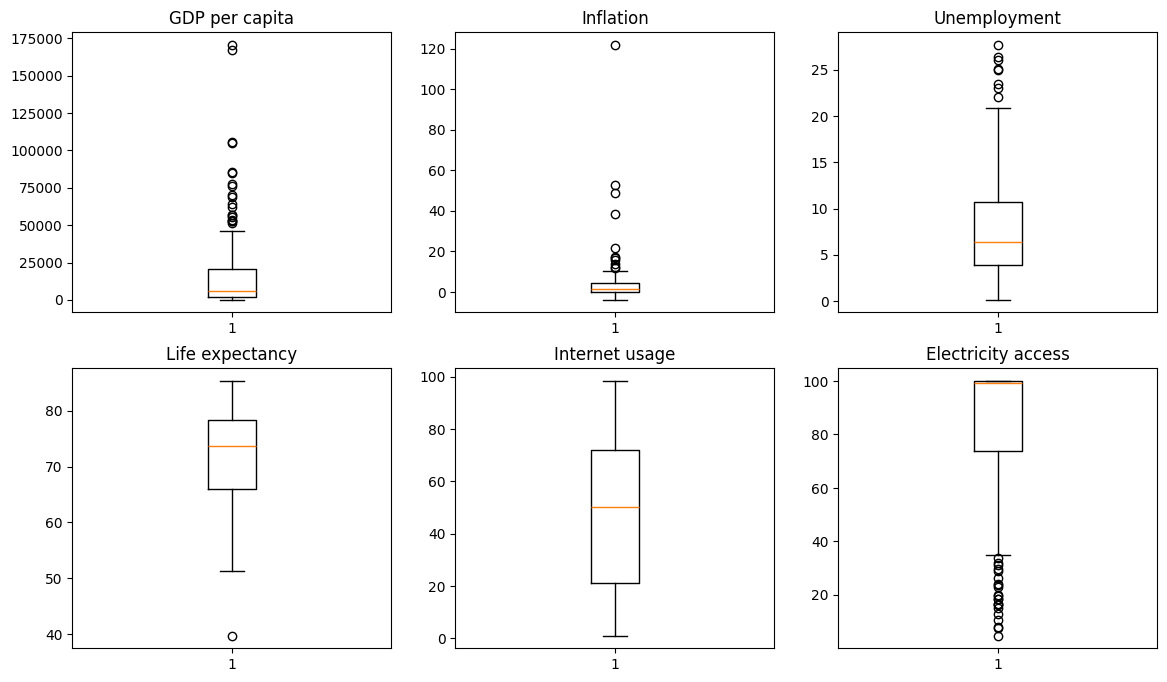

In [16]:
plt.figure(figsize=(14,8))
for i, col in enumerate(key_data.columns):
    plt.subplot(2, 3, i+1)
    plt.boxplot(key_data[col].dropna()) #since NaNs are present, boxplot wont give correct plot without dropna to remove NaNs
    plt.title(['GDP per capita', 'Inflation', 'Unemployment', 'Life expectancy', 'Internet usage', 'Electricity access'][i]);

The strongly skewed Indicators have large number of outliers, since their median is concentrated to one side
Life expectancy has just 1 outlier country - South Sudan (shown below)
Internet usage has no outliers.

In [17]:
q1, q3 = np.percentile(data['SP.DYN.LE00.IN'].dropna(), [25, 75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
data[data['SP.DYN.LE00.IN'] < lower][['Country Name', 'SP.DYN.LE00.IN']]

,Country Name,SP.DYN.LE00.IN
178,South Sudan,39.757


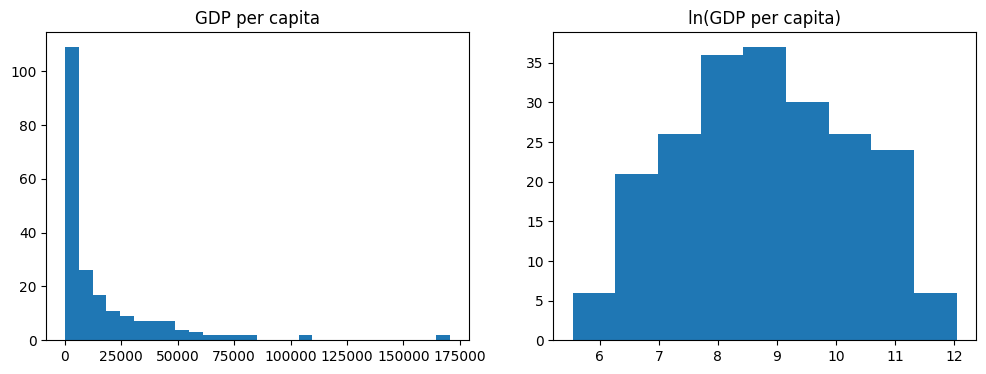

In [20]:
ln_trans_gdp = np.log(data['NY.GDP.PCAP.CD'].dropna())
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(data['NY.GDP.PCAP.CD'].dropna(), bins='auto')
plt.title('GDP per capita')

plt.subplot(1, 2, 2)
plt.hist(ln_trans_gdp, bins='auto')
plt.title('ln(GDP per capita)');


The highly right skewed GDP PC indicator on applying log transformation (natural ln), made it symmetric (as seen from above histogram) and hence reduced the skewness. Hence using transformed GDP would be more useful for our clustering, since the really high GDP PC countries would not have a huge influence on the squared distance.

### 3. Comparison of known income groups

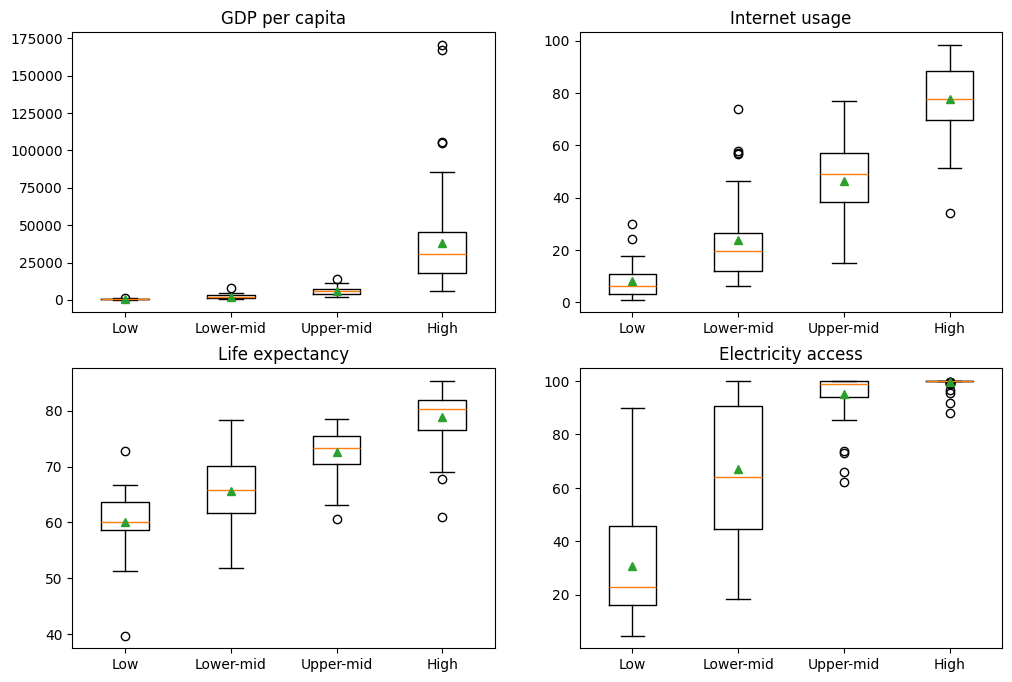

In [24]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(['NY.GDP.PCAP.CD', 'IT.NET.USER.ZS', 'SP.DYN.LE00.IN', 'EG.ELC.ACCS.ZS']):
    plt.subplot(2, 2, i+1)

    plt.boxplot([data[data['incomeLevel.value'] == 'Low income'][col].dropna(), data[data['incomeLevel.value'] == 'Lower middle income'][col].dropna(), data[data['incomeLevel.value'] == 'Upper middle income'][col].dropna(), data[data['incomeLevel.value'] == 'High income'][col].dropna()], tick_labels=['Low', 'Lower-mid', 'Upper-mid', 'High'], showmeans = True)

    plt.title(['GDP per capita', 'Internet usage', 'Life expectancy', 'Electricity access'][i])


Clearly for all 4 Indicators, High income countries (as classified by World Bank), have higher mean and median and they reduce as we move towards Low income countries.

### 4. Correlations between Indicators

In [22]:
corr = data[indicators].corr(method='pearson')
corr

,NY.GDP.PCAP.CD,NY.GDP.MKTP.KD.ZG,FP.CPI.TOTL.ZG,SL.UEM.TOTL.ZS,NE.TRD.GNFS.ZS,NE.GDI.TOTL.ZS,SP.DYN.LE00.IN,SP.URB.TOTL.IN.ZS,IT.NET.USER.ZS,EG.ELC.ACCS.ZS,SE.SEC.ENRR
NY.GDP.PCAP.CD,1.000000,-0.065625,-0.181044,-0.108601,0.364430,-0.101104,0.596484,0.430247,0.679852,0.375072,0.488621
NY.GDP.MKTP.KD.ZG,-0.065625,1.000000,-0.347511,-0.146928,0.115576,0.266027,-0.013631,-0.151636,-0.103582,-0.044329,-0.081862
FP.CPI.TOTL.ZG,-0.181044,-0.347511,1.000000,-0.014079,-0.141672,-0.089664,-0.219625,-0.007169,-0.153161,-0.124040,-0.172469
SL.UEM.TOTL.ZS,-0.108601,-0.146928,-0.014079,1.000000,0.033877,-0.154466,0.007691,0.103265,0.077823,0.139301,0.176846
NE.TRD.GNFS.ZS,0.364430,0.115576,-0.141672,0.033877,1.000000,-0.048187,0.284006,0.294384,0.346294,0.241397,0.276494
NE.GDI.TOTL.ZS,-0.101104,0.266027,-0.089664,-0.154466,-0.048187,1.000000,-0.007107,-0.132357,-0.085404,-0.008324,-0.116948
SP.DYN.LE00.IN,0.596484,-0.013631,-0.219625,0.007691,0.284006,-0.007107,1.000000,0.605656,0.851388,0.802864,0.792618
SP.URB.TOTL.IN.ZS,0.430247,-0.151636,-0.007169,0.103265,0.294384,-0.132357,0.605656,1.000000,0.690277,0.576834,0.572853
IT.NET.USER.ZS,0.679852,-0.103582,-0.153161,0.077823,0.346294,-0.085404,0.851388,0.690277,1.000000,0.754603,0.808816
EG.ELC.ACCS.ZS,0.375072,-0.044329,-0.124040,0.139301,0.241397,-0.008324,0.802864,0.576834,0.754603,1.000000,0.795080


From the table, it can be observed that GDP PC, Life expectancy and Internet Users have generally high correlations with other Indicators

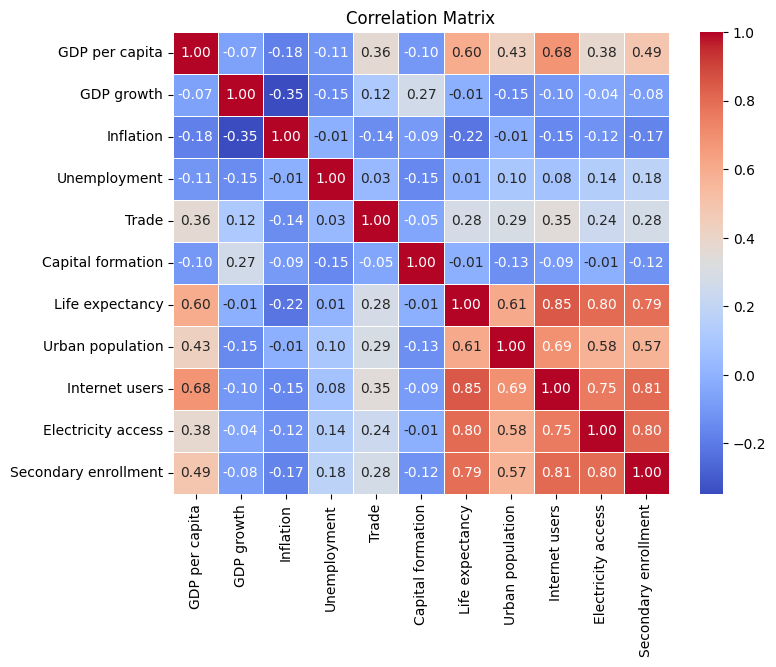

In [25]:
short = {'NY.GDP.PCAP.CD': 'GDP per capita', 'NY.GDP.MKTP.KD.ZG': 'GDP growth', 'FP.CPI.TOTL.ZG': 'Inflation', 'SL.UEM.TOTL.ZS': 'Unemployment', 'NE.TRD.GNFS.ZS': 'Trade', 'NE.GDI.TOTL.ZS': 'Capital formation', 'SP.DYN.LE00.IN': 'Life expectancy', 'SP.URB.TOTL.IN.ZS': 'Urban population', 'IT.NET.USER.ZS': 'Internet users', 'EG.ELC.ACCS.ZS': 'Electricity access', 'SE.SEC.ENRR': 'Secondary enrollment'}
plt.figure(figsize=(8, 6))
sns.heatmap(corr.rename(index=short, columns=short), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix');

(-1.0, 1.0)

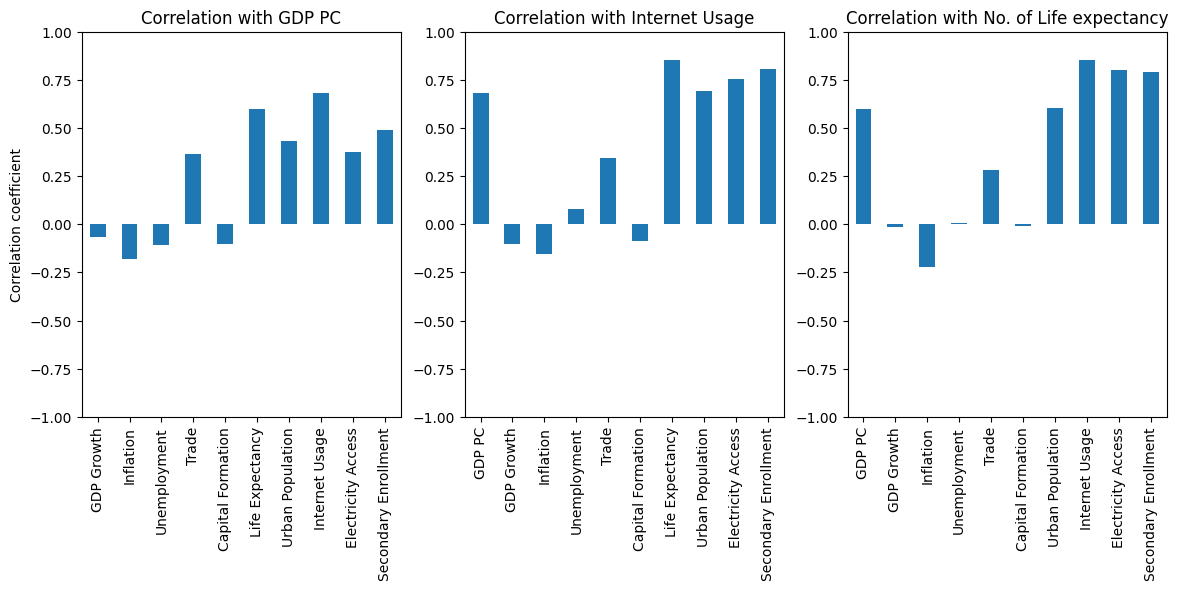

In [24]:
plt.figure(figsize=(14,5))
plt.subplot(1, 3, 1)
corr['NY.GDP.PCAP.CD'].drop('NY.GDP.PCAP.CD').rename(index={'NY.GDP.MKTP.KD.ZG': 'GDP Growth', 'FP.CPI.TOTL.ZG': 'Inflation', 'SL.UEM.TOTL.ZS': 'Unemployment', 'NE.TRD.GNFS.ZS': 'Trade', 'NE.GDI.TOTL.ZS': 'Capital Formation', 'SP.DYN.LE00.IN': 'Life Expectancy', 'SP.URB.TOTL.IN.ZS': 'Urban Population', 'IT.NET.USER.ZS': 'Internet Usage', 'EG.ELC.ACCS.ZS': 'Electricity Access', 'SE.SEC.ENRR': 'Secondary Enrollment'}).plot.bar()
#drop removes the row with same indicator (giving correlation 1)
plt.title('Correlation with GDP PC')
plt.ylabel('Correlation coefficient')
plt.ylim(-1, 1)

plt.subplot(1, 3, 2)
corr['IT.NET.USER.ZS'].drop('IT.NET.USER.ZS').rename(index={'NY.GDP.PCAP.CD': 'GDP PC', 'NY.GDP.MKTP.KD.ZG': 'GDP Growth', 'FP.CPI.TOTL.ZG': 'Inflation', 'SL.UEM.TOTL.ZS': 'Unemployment', 'NE.TRD.GNFS.ZS': 'Trade', 'NE.GDI.TOTL.ZS': 'Capital Formation', 'SP.DYN.LE00.IN': 'Life Expectancy', 'SP.URB.TOTL.IN.ZS': 'Urban Population', 'EG.ELC.ACCS.ZS': 'Electricity Access', 'SE.SEC.ENRR': 'Secondary Enrollment'}).plot.bar()
plt.title('Correlation with Internet Usage')
plt.ylim(-1, 1)

plt.subplot(1, 3, 3)
corr['SP.DYN.LE00.IN'].drop('SP.DYN.LE00.IN').rename(index={'NY.GDP.PCAP.CD': 'GDP PC', 'NY.GDP.MKTP.KD.ZG': 'GDP Growth', 'FP.CPI.TOTL.ZG': 'Inflation', 'SL.UEM.TOTL.ZS': 'Unemployment', 'NE.TRD.GNFS.ZS': 'Trade', 'NE.GDI.TOTL.ZS': 'Capital Formation', 'SP.URB.TOTL.IN.ZS': 'Urban Population', 'IT.NET.USER.ZS': 'Internet Usage', 'EG.ELC.ACCS.ZS': 'Electricity Access', 'SE.SEC.ENRR': 'Secondary Enrollment'}).plot.bar()
plt.title('Correlation with No. of Life expectancy')
plt.ylim(-1, 1)

We can see that GDP is highly correlated to Internet Users and Life Expectancy. This is expected as countries with high average income, have more people who can access the internet and healthcare facilities hence having higher life expectancy. It has weak correlations with GDP growth, Inflation and Unemployment.

Internet usage and Life expectancy are even more strongly correlated with each other, and both show strong correlations with Electricity access and Secondary enrollment. GDP growth, inflation and capital formation show relatively weak correlations with most of these indicators.

### 5. Pairwise Relationships

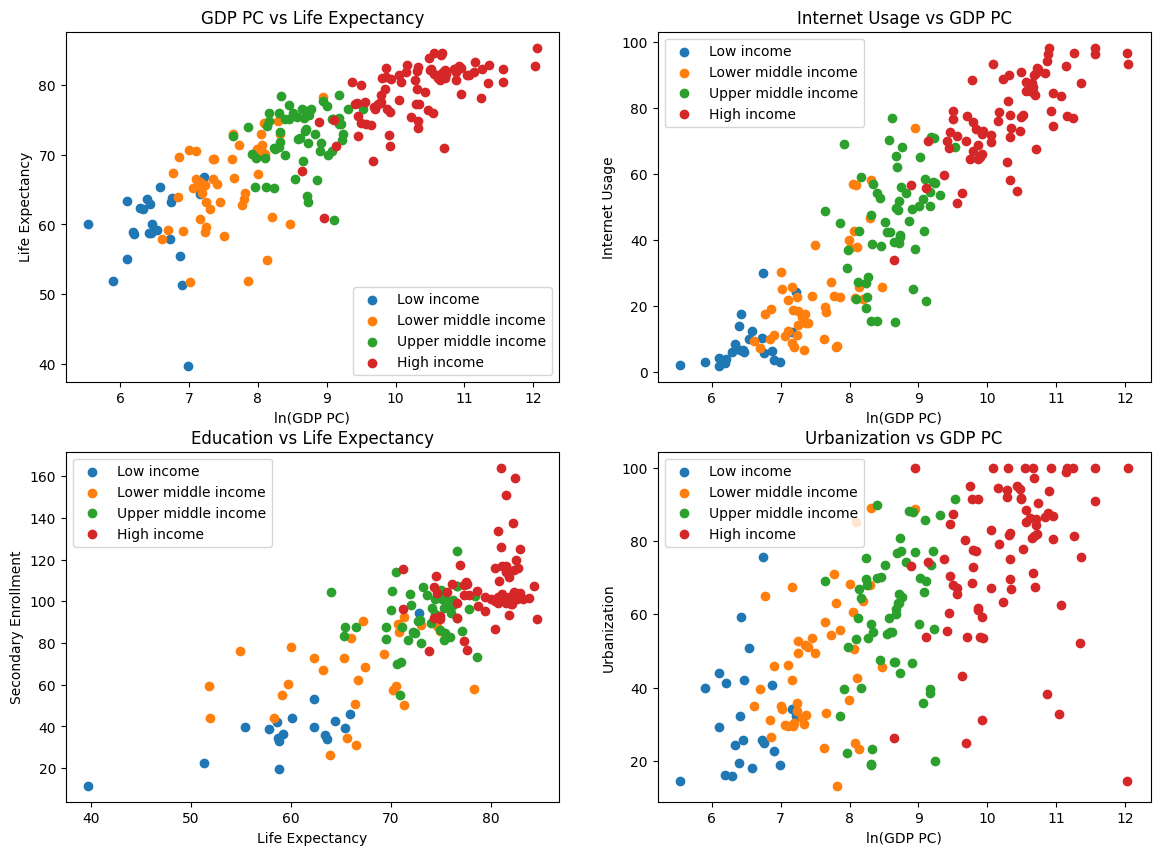

In [25]:
plt.figure(figsize=(14, 10))

for group in ['Low income', 'Lower middle income', 'Upper middle income', 'High income']:

    plt.subplot(2, 2, 1)
    plt.scatter(np.log(data[data['incomeLevel.value'] == group]['NY.GDP.PCAP.CD']), data[data['incomeLevel.value'] == group]['SP.DYN.LE00.IN'], label=group)
    plt.title('GDP PC vs Life Expectancy')
    plt.xlabel('ln(GDP PC)')
    plt.ylabel('Life Expectancy')
    plt.legend()

    plt.subplot(2, 2, 2)
    plt.scatter(np.log(data[data['incomeLevel.value'] == group]['NY.GDP.PCAP.CD']), data[data['incomeLevel.value'] == group]['IT.NET.USER.ZS'], label=group)
    plt.title('Internet Usage vs GDP PC')
    plt.xlabel('ln(GDP PC)')
    plt.ylabel('Internet Usage')
    plt.legend()

    plt.subplot(2, 2, 3)
    plt.scatter(data[data['incomeLevel.value'] == group]['SP.DYN.LE00.IN'], data[data['incomeLevel.value'] == group]['SE.SEC.ENRR'], label=group)
    plt.title('Education vs Life Expectancy')
    plt.xlabel('Life Expectancy')
    plt.ylabel('Secondary Enrollment')
    plt.legend()

    plt.subplot(2, 2, 4)
    plt.scatter(np.log(data[data['incomeLevel.value'] == group]['NY.GDP.PCAP.CD']), data[data['incomeLevel.value'] == group]['SP.URB.TOTL.IN.ZS'], label=group)
    plt.title('Urbanization vs GDP PC')
    plt.xlabel('ln(GDP PC)')
    plt.ylabel('Urbanization')
    plt.legend()

    #We had to take Transformed GDP PC because normally it was showing a heavily skewed plot where most values were concentrated to the left

All plots show a positive relationship between the Indicators. First plot shows Life expectancy increases with income, but the increase appears to slow down among high income countries.\
Low income countries having low internet usage and high income countries generally having much higher usage.\
Same can be seen with countries with higher secondary enrollment which generally have higher life expectancy, although it has some variation for high income countries.\
Urbanization is a more scattered plot indicating even some high income countries can have low urban population

## Data Preprocessing

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

In [32]:
impute = SimpleImputer(strategy='median')
X = data[indicators] 

X['NY.GDP.PCAP.CD'] = np.log(X['NY.GDP.PCAP.CD'])
#Using log (natural ln) transformed, makes the shape symmeteric ensuring extremely skewed GDP countries do not have high in influence their PCA/KMeans analysis.

X = impute.fit_transform(X)
#First we fill up NaN values using median imputation, i.e, put median instead of NaNs
#We used median because our data contains extremely skewed columns

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Standardization was important before PCA since feature such as GDP, which has a large scale would dominate/ have a large influence on the results.

In [41]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)
pca.explained_variance_ratio_

array([0.42390455, 0.13892617, 0.09425774, 0.08467748, 0.07436386,
       0.0557128 , 0.04518969, 0.03413676, 0.02602876, 0.01332624,
       0.00947595])

In [ ]:
pca.explained_variance_ratio_[:7].sum()
#First 7 components capture more than 90% variation while PC1 gives 42.4%

np.float64(0.9170322919502849)

In [47]:
new_ind = ['ln(GDP PC)', 'GDP Growth', 'Inflation', 'Unemployment', 'Trade', 'Capital Formation', 'Life Expectancy', 'Urban Population', 'Internet Usage', 'Electricity Access', 'Secondary Enrollment']
pd.DataFrame(pca.components_[:7].T, index=new_ind, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7'])

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
ln(GDP PC),0.426886,0.012814,-0.058139,0.053042,-0.080475,-0.095077,0.079544
GDP Growth,-0.041291,0.639282,0.174804,0.028217,0.087174,0.715214,0.146592
Inflation,-0.103194,-0.467241,-0.488633,0.100158,0.502323,0.471911,-0.133671
Unemployment,0.045744,-0.316907,0.682090,-0.461543,0.406086,0.046616,0.137616
Trade,0.178493,0.169998,0.282683,0.685966,0.526997,-0.239825,-0.201505
Capital Formation,-0.042145,0.465852,-0.375854,-0.464600,0.516499,-0.387107,0.018805
Life Expectancy,0.421304,0.084403,-0.113755,-0.069981,-0.083444,0.056226,-0.029531
Urban Population,0.348897,-0.135755,-0.107680,0.109197,0.118253,0.022885,0.719472
Internet Usage,0.427835,-0.017311,-0.077565,0.002646,-0.025866,0.000078,0.033570
Electricity Access,0.397673,0.010154,-0.064198,-0.187955,0.039071,0.165284,-0.121884


Components -
PC1 majorly consists of GDP PC (transformed), Internet, Life expectancy, Electricity representing overall socioeconomic development\
This suggests that countries with higher PC1 scores generally show higher levels of socioeconomic development

PC2 has GDP growth, Inflation and Capital formation, which represent economic growth\
Inflation is affected negatively hence PC2 represents difference in GDP growth and investment relative to inflation.

PC3 consists Inflation, Unemployment, capital formation\
Unemployment is affected positively while the other two negatively.

PC4 and PC5 are influenced mainly by trade, capital formation, unemployment and inflation, capturing further differences in macroeconomic \
conditions. PC6 is strongly influenced by GDP growth, while PC7 contrasts urbanization and secondary enrollment (negative).

## Clustering Algorithms

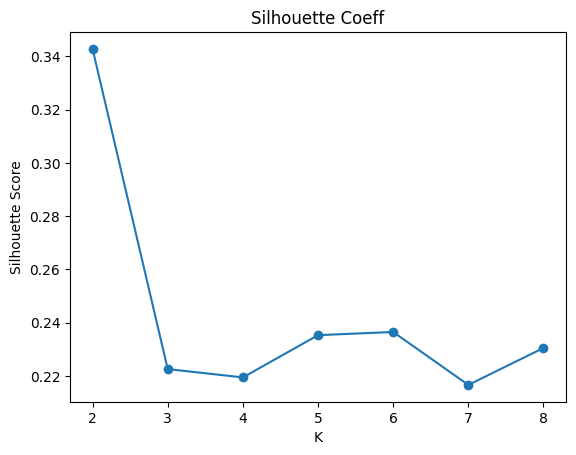

In [59]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_pca[:, :7]) #choosing 7 components for every country's data
    silhouette.append(silhouette_score(X_pca[:, :7], labels))

plt.plot(range(2, 9), silhouette, marker='o')
plt.xlabel('K')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Coeff');

Using the Silhouette Coefficient method, we decide the number of clusters to be 2\
In this, KMeans was done for K = 2 to 8 and K = 2 gave the highest Silhouette score

In [60]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_pca[:, :7])

clustered = data.copy()
clustered['Cluster'] = labels

clustered['Cluster'].value_counts()

Cluster
0    145
1     72
Name: count, dtype: int64

In [61]:
clustered.groupby('Cluster')[indicators].median().T

Cluster,0,1
NY.GDP.PCAP.CD,14082.654850,1319.592974
NY.GDP.MKTP.KD.ZG,2.390554,4.092172
FP.CPI.TOTL.ZG,0.798631,3.550760
SL.UEM.TOTL.ZS,7.421000,4.514000
NE.TRD.GNFS.ZS,87.248531,57.932131
NE.GDI.TOTL.ZS,23.595528,25.118005
SP.DYN.LE00.IN,76.563000,63.746500
SP.URB.TOTL.IN.ZS,73.103058,35.069106
IT.NET.USER.ZS,68.020026,14.900000
EG.ELC.ACCS.ZS,100.000000,53.600000


Hence, KMeans with K = 2 divided the 217 countries into 2 clusters of 145 and 72 countries. Cluster 0 shows considerably higher GDP per capita, life expectancy, internet usage, electricity access and secondary enrollment, suggesting relatively higher socioeconomic development. Cluster 1 has lower values across these indicators.\
On the other hand, Cluster 1 has higher median GDP growth, while Cluster 0 has higher median unemployment.

In [63]:
pd.crosstab(clustered['Cluster'], clustered['incomeLevel.value'], normalize='index') * 100

incomeLevel.value,High income,Low income,Lower middle income,Upper middle income
Cluster,,,,
0,58.620690,0.689655,6.206897,34.482759
1,1.388889,33.333333,52.777778,12.500000


As expected, Cluster 0 majorly consists of countries classified as Upper middle to High income (93.10%)\
while Cluster 1 has majority Low and Lower Middle income countries (86.11%).\
This shows that the unsupervised clusters from KMeans, align with World Bank classifications based on income.

In [65]:
clustered[(clustered['Cluster'] == 0) & (clustered['incomeLevel.value'] == 'Low income')]

,Country Name,Country Code,EG.ELC.ACCS.ZS,FP.CPI.TOTL.ZG,IT.NET.USER.ZS,NE.GDI.TOTL.ZS,NE.TRD.GNFS.ZS,NY.GDP.MKTP.KD.ZG,NY.GDP.PCAP.CD,SE.SEC.ENRR,SL.UEM.TOTL.ZS,SP.DYN.LE00.IN,SP.URB.TOTL.IN.ZS,region.value,lendingType.value,incomeLevel.value,Cluster
103,"Korea, Dem. People's Rep.",PRK,40.0,NaN,NaN,NaN,NaN,NaN,NaN,94.251541,3.523,72.825,61.324757,East Asia & Pacific,Not classified,Low income,0


Clearly, due to the unavaiability of GDP PC, GDP growth, Inflation and other indicators, even though World Bank classified it as Low income, due to imputation in our dataset, it was put in cluster 0, that is, the high income bracket

In [67]:
clustered[(clustered['Cluster'] == 1) & (clustered['incomeLevel.value'] == 'High income')]

,Country Name,Country Code,EG.ELC.ACCS.ZS,FP.CPI.TOTL.ZG,IT.NET.USER.ZS,NE.GDI.TOTL.ZS,NE.TRD.GNFS.ZS,NY.GDP.MKTP.KD.ZG,NY.GDP.PCAP.CD,SE.SEC.ENRR,SL.UEM.TOTL.ZS,SP.DYN.LE00.IN,SP.URB.TOTL.IN.ZS,region.value,lendingType.value,incomeLevel.value,Cluster
83,Guyana,GUY,88.0,-0.865401,34.0,NaN,NaN,0.687405,5640.415606,NaN,13.009,67.719,26.404392,Latin America & Caribbean,IDA,High income,1


Guyana's GDP PC was higher than the Cluster 1 median but its Internet usage, Life expectancy and Urbanization were substantially below the Cluster 0 medians, hence KMeans placed it in Cluster 1.\
Also the World Bank classifications are recent, however our Indicators are from 2015. Hence the discrepancy.

### Hierarchical Clustering

It is another clustering algorithm similar to KMeans\
It forms clusters by progressively building groups by combining similar observations.\
We will use agglomerative Clustering: It starts with every country in its own cluster and then we progressively merge similar clusters.\
The merging happens based on distance as measured by Ward Linkage method - It merges the pair with smallest increase in within cluster variance

In [68]:
from sklearn.cluster import AgglomerativeClustering

hier = AgglomerativeClustering(n_clusters=2, linkage='ward')
hier_labels = hier.fit_predict(X_pca[:, :7])

pd.crosstab(labels, hier_labels)

col_0,0,1
row_0,,
0,145,0
1,28,44


Rows are KMeans Clusters, and Cols are Hierarchical Clusters.\
They show different results since they perform different algorithms, and do not necessarily have to agree.

Hierarchical Clustering put 173 countries in Cluster 0 and 44 in Cluster 1

In [70]:
clustered['Hierarchical'] = hier_labels

clustered[clustered['Cluster'] != clustered['Hierarchical']]

,Country Name,Country Code,EG.ELC.ACCS.ZS,FP.CPI.TOTL.ZG,IT.NET.USER.ZS,NE.GDI.TOTL.ZS,NE.TRD.GNFS.ZS,NY.GDP.MKTP.KD.ZG,NY.GDP.PCAP.CD,SE.SEC.ENRR,SL.UEM.TOTL.ZS,SP.DYN.LE00.IN,SP.URB.TOTL.IN.ZS,region.value,lendingType.value,incomeLevel.value,Cluster,Hierarchical
15,Bangladesh,BGD,74.0,6.194280,12.368800,28.886689,42.085996,6.552640,1224.386477,59.421741,4.397,70.54300,29.539510,South Asia,IDA,Lower middle income,1,0
22,Bhutan,BTN,95.4,4.548144,39.799999,56.431110,89.639160,6.660801,2954.040819,85.231308,2.450,70.79700,36.698338,South Asia,IDA,Lower middle income,1,0
33,Cambodia,KHM,62.7,1.223932,6.433191,29.871494,122.109597,7.207035,1547.320104,NaN,0.393,69.39800,30.066922,East Asia & Pacific,IDA,Lower middle income,1,0
45,"Congo, Rep.",COG,44.3,3.169098,7.616000,76.782325,117.320722,0.415193,2439.351894,NaN,20.020,63.66200,63.135593,Sub-Saharan Africa,Blend,Lower middle income,1,0
60,Equatorial Guinea,GNQ,66.1,1.676631,21.320000,24.701453,98.878059,-9.110041,9068.910032,NaN,7.778,60.63500,68.951271,Sub-Saharan Africa,IBRD,Upper middle income,1,0
80,Guatemala,GTM,90.5,2.388720,28.805901,14.828155,49.893452,4.092172,3893.505333,54.886419,2.506,70.91500,53.441105,Latin America & Caribbean,IBRD,Upper middle income,1,0
83,Guyana,GUY,88.0,-0.865401,34.000000,NaN,NaN,0.687405,5640.415606,NaN,13.009,67.71900,26.404392,Latin America & Caribbean,IDA,High income,1,0
85,Honduras,HND,90.0,3.157831,27.139545,25.118005,107.264405,3.840080,2271.202660,50.351109,6.147,71.32300,54.382847,Latin America & Caribbean,IDA,Lower middle income,1,0
89,India,IND,88.0,4.906973,14.900000,32.116730,41.922914,7.996254,1583.998159,74.611366,7.629,69.32600,32.547299,South Asia,IBRD,Lower middle income,1,0
90,Indonesia,IDN,97.5,6.363121,22.062743,34.062792,41.937640,4.876322,3288.222697,87.842321,4.514,69.52000,53.172077,East Asia & Pacific,IBRD,Upper middle income,1,0


28 Countries where the 2 methods give different results

In [71]:
pd.crosstab(clustered['Hierarchical'], clustered['incomeLevel.value'], normalize='index') * 100

incomeLevel.value,High income,Low income,Lower middle income,Upper middle income
Hierarchical,,,,
0,49.710983,2.312139,13.872832,34.104046
1,0.000000,47.727273,52.272727,0.000000


Similarities:\
Both methods divided the countries broadly into higher income and lower income groups.\
Both showed a strong relationship with World Bank income classifications.\
All 145 countries in KMeans Cluster 0 also belong to Hierarchical Cluster 0.

Differences:\
Hierarchical Cluster 1 consists entirely of Low and Lower middle income countries, whereas KMeans Cluster 1 also contains some Upper middle and High Income countries.\
They also differ in the way they calculate clusters